# Lab: Hyperparameter Fine-Tuning of CNNs (PyTorch + CIFAR-10)

**Course:** Artificial Neural Networks and Deep Learning  
**Dataset:** CIFAR-10  
**Platform:** Google Colab (GPU recommended)

## Learning objectives
- Build a configurable CNN.
- Investigate architecture parameters: convolutional layers, filters, dense neurons, activation, padding, pooling.
- Investigate training parameters: optimizer, learning rate, batch size, dropout, weight decay, epochs.
- Compare experiments using validation accuracy, loss, and training time.

> **Experimental fairness:** Change one parameter at a time in each comparison. Use the same data split and random seed. Results may vary slightly due to hardware and stochastic training.

## Suggested workflow
1. Run the setup and data cells.
2. Train the baseline.
3. Run selected experiments in the sweep cell (start with fewer epochs for a lab session).
4. Review the comparison table and plots.
5. Write observations and a justified final configuration.


In [1]:
# 1. Imports, reproducibility, and device
import time, copy, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


Device: cpu


100%|██████████| 170M/170M [39:31<00:00, 71.9kB/s]


Train: 45000 | Validation: 5000 | Test: 10000
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


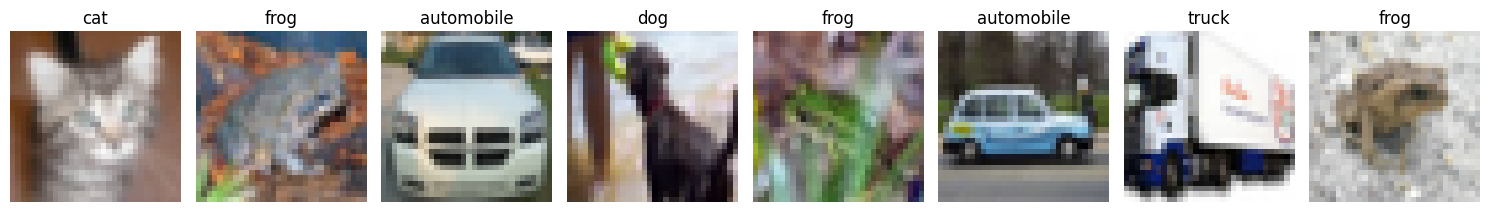

In [ ]:
# 2. Load CIFAR-10 and create train/validation/test splits
# CIFAR-10 images: 3 channels, 32 x 32; 10 classes.
# Normalization values are commonly used for CIFAR-10.
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465),
                         (0.2470, 0.2435, 0.2616))
])

full_train = datasets.CIFAR10(root="./data", train=True, download=True, transform=transform)
test_dataset = datasets.CIFAR10(root="./data", train=False, download=True, transform=transform)

train_size = 45_000
val_size = 5_000
train_dataset, val_dataset = random_split(
    full_train, [train_size, val_size],
    generator=torch.Generator().manual_seed(SEED)
)

class_names = full_train.classes
print("Train:", len(train_dataset), "| Validation:", len(val_dataset), "| Test:", len(test_dataset))
print("Classes:", class_names)

# Display a few training images (denormalize for display)
def show_samples(dataset, count=8):
    loader = DataLoader(dataset, batch_size=count, shuffle=True)
    images, labels = next(iter(loader))
    mean = torch.tensor((0.4914, 0.4822, 0.4465)).view(3,1,1)
    std = torch.tensor((0.2470, 0.2435, 0.2616)).view(3,1,1)
    images = (images * std + mean).clamp(0,1)
    fig, axes = plt.subplots(1, count, figsize=(15,2.5))
    for i, ax in enumerate(axes):
        ax.imshow(images[i].permute(1,2,0))
        ax.set_title(class_names[labels[i]])
        ax.axis("off")
    plt.tight_layout()
    plt.show()

show_samples(train_dataset)


In [ ]:
# 3. Configurable CNN architecture
# Padding choices:
#   "same"  -> preserve spatial dimensions for 3x3, stride 1
#   "valid"  -> no padding, spatial dimensions shrink
# Pooling choices: "max" or "avg"
# Activations: "relu", "leaky_relu", "tanh"

def get_activation(name):
    name = name.lower()
    if name == "relu":
        return nn.ReLU()
    elif name == "leaky_relu":
        return nn.LeakyReLU(negative_slope=0.01)
    elif name == "tanh":
        return nn.Tanh()
    else:
        raise ValueError("Activation must be relu, leaky_relu, or tanh.")

def get_pool(name):
    name = name.lower()
    if name == "max":
        return nn.MaxPool2d(kernel_size=2, stride=2)
    elif name == "avg":
        return nn.AvgPool2d(kernel_size=2, stride=2)
    else:
        raise ValueError("Pooling must be max or avg.")

class ConfigurableCNN(nn.Module):
    def __init__(
        self,
        conv_channels=(32, 64),
        dense_neurons=128,
        dense_layers=1,
        activation="relu",
        padding="same",
        pooling="max",
        dropout=0.3,
        num_classes=10,
        input_channels=3,
        image_size=32
    ):
        super().__init__()
        if dense_layers < 1:
            raise ValueError("dense_layers must be >= 1")
        if padding not in ("same", "valid"):
            raise ValueError("padding must be 'same' or 'valid'")

        pad = 1 if padding == "same" else 0
        act = get_activation(activation)

        # Build convolutional feature extractor
        feature_layers = []
        in_channels = input_channels
        for out_channels in conv_channels:
            feature_layers += [
                nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=pad),
                nn.BatchNorm2d(out_channels),
                get_activation(activation),
                get_pool(pooling)
            ]
            in_channels = out_channels
        self.features = nn.Sequential(*feature_layers)

        # Automatically calculate flattened feature size
        with torch.no_grad():
            dummy = torch.zeros(1, input_channels, image_size, image_size)
            try:
                flattened_size = self.features(dummy).view(1, -1).shape[1]
            except Exception as e:
                raise ValueError(
                    "The selected convolution/pooling configuration makes the image too small. "
                    "Try fewer conv layers or use padding='same'."
                ) from e

        # Build fully connected classifier
        classifier = []
        in_features = flattened_size
        for _ in range(dense_layers):
            classifier += [
                nn.Linear(in_features, dense_neurons),
                get_activation(activation),
                nn.Dropout(p=dropout)
            ]
            in_features = dense_neurons
        classifier.append(nn.Linear(in_features, num_classes))
        self.classifier = nn.Sequential(*classifier)

    def forward(self, x):
        x = self.features(x)
        x = torch.flatten(x, start_dim=1)
        x = self.classifier(x)
        return x  # raw logits; CrossEntropyLoss applies softmax internally

# Baseline configuration
baseline_config = {
    "conv_channels": (32, 64),
    "dense_neurons": 128,
    "dense_layers": 1,
    "activation": "relu",
    "padding": "same",
    "pooling": "max",
    "dropout": 0.3
}

baseline_model = ConfigurableCNN(**baseline_config).to(device)
print(baseline_model)


ConfigurableCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Linear(in_features=4096, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)


In [ ]:
# 4. Training and evaluation functions
# These functions return metrics and learning history for each experiment.

def make_optimizer(model, optimizer_name="adam", lr=0.001, weight_decay=0.0):
    name = optimizer_name.lower()
    if name == "adam":
        return optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    elif name == "sgd":
        return optim.SGD(model.parameters(), lr=lr, momentum=0.9,
                         weight_decay=weight_decay)
    elif name == "rmsprop":
        return optim.RMSprop(model.parameters(), lr=lr, weight_decay=weight_decay)
    else:
        raise ValueError("Optimizer must be adam, sgd, or rmsprop.")

def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train() if training else model.eval()

    total_loss, correct, total = 0.0, 0, 0
    context = torch.enable_grad() if training else torch.no_grad()

    with context:
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)

            if training:
                optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            if training:
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * images.size(0)
            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    return total_loss / total, 100.0 * correct / total

def train_model(config, epochs=5, batch_size=128, optimizer_name="adam",
               lr=0.001, weight_decay=0.0, verbose=True):
    # DataLoaders use the same train/validation split for every experiment.
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True,
                              num_workers=2, pin_memory=(device.type=="cuda"))
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False,
                            num_workers=2, pin_memory=(device.type=="cuda"))

    model = ConfigurableCNN(**config).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = make_optimizer(model, optimizer_name, lr, weight_decay)

    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    start_time = time.time()

    for epoch in range(1, epochs + 1):
        train_loss, train_acc = run_epoch(model, train_loader, criterion, optimizer)
        val_loss, val_acc = run_epoch(model, val_loader, criterion, optimizer=None)

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        if verbose:
            print(f"Epoch {epoch:02d}/{epochs} | "
                  f"Train loss {train_loss:.4f}, acc {train_acc:.2f}% | "
                  f"Val loss {val_loss:.4f}, acc {val_acc:.2f}%")

    elapsed = time.time() - start_time
    result = {
        "model": model,
        "history": history,
        "train_time_sec": elapsed,
        "final_train_acc": history["train_acc"][-1],
        "final_val_acc": history["val_acc"][-1],
        "final_train_loss": history["train_loss"][-1],
        "final_val_loss": history["val_loss"][-1]
    }
    return result

def plot_history(history, title="Learning Curves"):
    epochs = range(1, len(history["train_acc"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(epochs, history["train_acc"], marker="o", label="Train")
    axes[0].plot(epochs, history["val_acc"], marker="o", label="Validation")
    axes[0].set_title("Accuracy")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Accuracy (%)")
    axes[0].legend()
    axes[0].grid(True)

    axes[1].plot(epochs, history["train_loss"], marker="o", label="Train")
    axes[1].plot(epochs, history["val_loss"], marker="o", label="Validation")
    axes[1].set_title("Loss")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Loss")
    axes[1].legend()
    axes[1].grid(True)

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


Epoch 01/3 | Train loss 1.4313, acc 48.35% | Val loss 1.1007, acc 61.30%
Epoch 02/3 | Train loss 1.0914, acc 61.20% | Val loss 1.0141, acc 64.80%
Epoch 03/3 | Train loss 0.9807, acc 65.24% | Val loss 0.9454, acc 66.38%


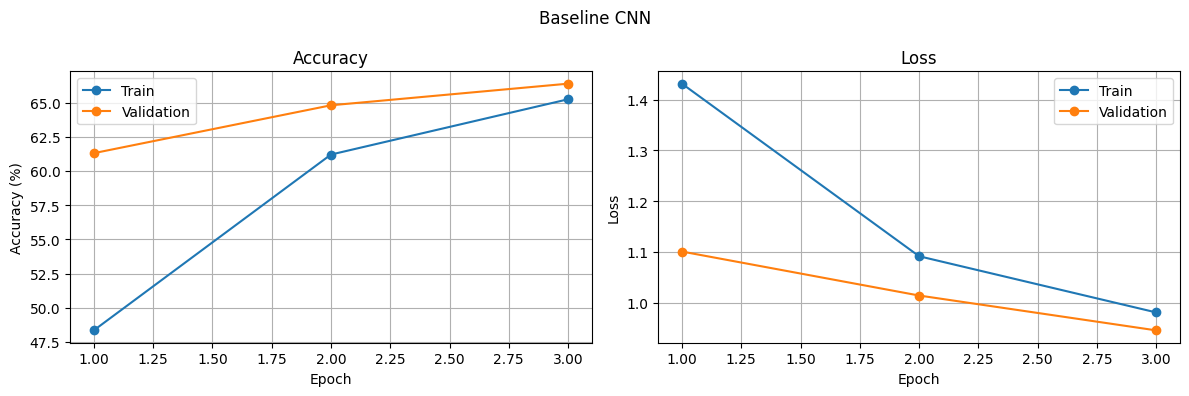

Baseline validation accuracy: 66.38%
Baseline training time: 295.6 seconds


In [ ]:
# 5. Train the baseline CNN
# For a short lab, begin with 3-5 epochs. Increase epochs for more reliable comparisons.
EPOCHS = 3
BATCH_SIZE = 128
BASE_OPTIMIZER = "adam"
BASE_LR = 0.001
BASE_WEIGHT_DECAY = 0.0

baseline_result = train_model(
    baseline_config,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    optimizer_name=BASE_OPTIMIZER,
    lr=BASE_LR,
    weight_decay=BASE_WEIGHT_DECAY
)

plot_history(baseline_result["history"], "Baseline CNN")
print(f"Baseline validation accuracy: {baseline_result['final_val_acc']:.2f}%")
print(f"Baseline training time: {baseline_result['train_time_sec']:.1f} seconds")


## 6. Controlled architecture experiments

The following experiments change **one architectural variable at a time** relative to the baseline:
- Dense neurons: 64, 128, 256
- Dense layers: 1, 2, 3
- Number of convolutional layers: 1, 2, 3
- Filter counts: compare a smaller and larger configuration
- Activation: ReLU, Leaky ReLU, Tanh
- Padding: same vs valid
- Pooling: max vs average

**Runtime tip:** For a 3-hour lab, run a subset first. Each experiment trains a new model from scratch.


In [ ]:
# 7. Experiment runner and results table
experiment_results = []

def run_experiment(name, config_updates=None, training_updates=None, epochs=EPOCHS):
    config = copy.deepcopy(baseline_config)
    if config_updates:
        config.update(config_updates)

    training = {
        "batch_size": BATCH_SIZE,
        "optimizer_name": BASE_OPTIMIZER,
        "lr": BASE_LR,
        "weight_decay": BASE_WEIGHT_DECAY
    }
    if training_updates:
        training.update(training_updates)

    print("\n" + "="*80)
    print("Experiment:", name)
    print("Architecture:", config)
    print("Training settings:", training)
    result = train_model(config, epochs=epochs, **training)
    plot_history(result["history"], name)

    experiment_results.append({
        "Experiment": name,
        "Conv layers": len(config["conv_channels"]),
        "Filters": str(config["conv_channels"]),
        "Dense layers": config["dense_layers"],
        "Dense neurons/layer": config["dense_neurons"],
        "Activation": config["activation"],
        "Padding": config["padding"],
        "Pooling": config["pooling"],
        "Dropout": config["dropout"],
        "Optimizer": training["optimizer_name"],
        "Learning rate": training["lr"],
        "Batch size": training["batch_size"],
        "Weight decay": training["weight_decay"],
        "Train accuracy (%)": result["final_train_acc"],
        "Validation accuracy (%)": result["final_val_acc"],
        "Train loss": result["final_train_loss"],
        "Validation loss": result["final_val_loss"],
        "Time (sec)": result["train_time_sec"]
    })
    return result

def show_results():
    if not experiment_results:
        print("No experiments completed yet.")
        return
    df = pd.DataFrame(experiment_results)
    display(df.sort_values("Validation accuracy (%)", ascending=False).reset_index(drop=True))
    return df

# Run the baseline configuration as a reference in the comparison table.
experiment_results.append({
    "Experiment": "Baseline",
    "Conv layers": len(baseline_config["conv_channels"]),
    "Filters": str(baseline_config["conv_channels"]),
    "Dense layers": baseline_config["dense_layers"],
    "Dense neurons/layer": baseline_config["dense_neurons"],
    "Activation": baseline_config["activation"],
    "Padding": baseline_config["padding"],
    "Pooling": baseline_config["pooling"],
    "Dropout": baseline_config["dropout"],
    "Optimizer": BASE_OPTIMIZER,
    "Learning rate": BASE_LR,
    "Batch size": BATCH_SIZE,
    "Weight decay": BASE_WEIGHT_DECAY,
    "Train accuracy (%)": baseline_result["final_train_acc"],
    "Validation accuracy (%)": baseline_result["final_val_acc"],
    "Train loss": baseline_result["final_train_loss"],
    "Validation loss": baseline_result["final_val_loss"],
    "Time (sec)": baseline_result["train_time_sec"]
})



Experiment: Dense neurons = 64
Architecture: {'conv_channels': (32, 64), 'dense_neurons': 64, 'dense_layers': 1, 'activation': 'relu', 'padding': 'same', 'pooling': 'max', 'dropout': 0.3}
Training settings: {'batch_size': 128, 'optimizer_name': 'adam', 'lr': 0.001, 'weight_decay': 0.0}
Epoch 01/3 | Train loss 1.5183, acc 44.56% | Val loss 1.1447, acc 58.90%
Epoch 02/3 | Train loss 1.2090, acc 56.65% | Val loss 1.0653, acc 62.42%
Epoch 03/3 | Train loss 1.0970, acc 60.64% | Val loss 0.9508, acc 67.18%


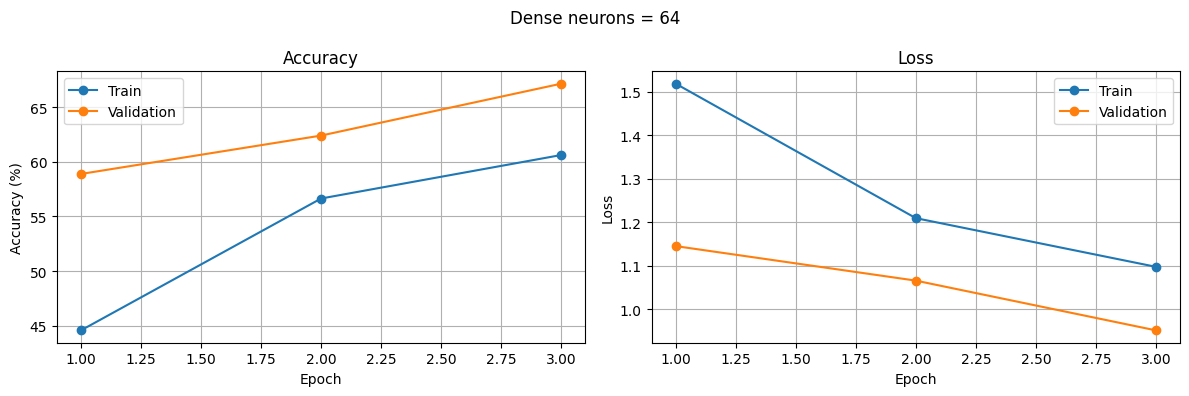


Experiment: Dense neurons = 256
Architecture: {'conv_channels': (32, 64), 'dense_neurons': 256, 'dense_layers': 1, 'activation': 'relu', 'padding': 'same', 'pooling': 'max', 'dropout': 0.3}
Training settings: {'batch_size': 128, 'optimizer_name': 'adam', 'lr': 0.001, 'weight_decay': 0.0}
Epoch 01/3 | Train loss 1.4293, acc 48.43% | Val loss 1.1032, acc 60.98%
Epoch 02/3 | Train loss 1.0884, acc 61.26% | Val loss 1.0703, acc 62.34%
Epoch 03/3 | Train loss 0.9690, acc 65.78% | Val loss 0.9336, acc 66.94%


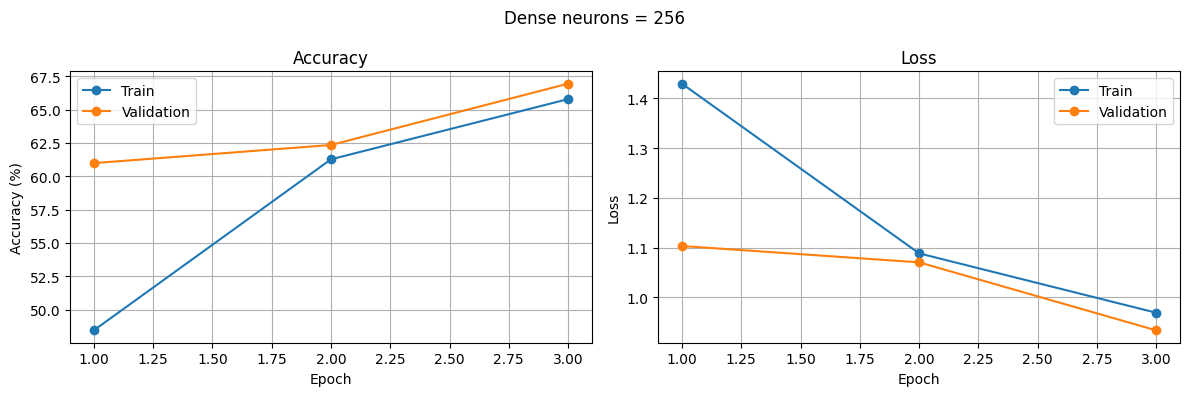

,Experiment,Conv layers,Filters,Dense layers,Dense neurons/layer,Activation,Padding,Pooling,Dropout,Optimizer,Learning rate,Batch size,Weight decay,Train accuracy (%),Validation accuracy (%),Train loss,Validation loss,Time (sec)
0,Dense neurons = 64,2,"(32, 64)",1,64,relu,same,max,0.3,adam,0.001,128,0.0,60.637778,67.18,1.096969,0.950818,282.689281
1,Dense neurons = 256,2,"(32, 64)",1,256,relu,same,max,0.3,adam,0.001,128,0.0,65.782222,66.94,0.969018,0.933620,298.363139
2,Baseline,2,"(32, 64)",1,128,relu,same,max,0.3,adam,0.001,128,0.0,65.240000,66.38,0.980732,0.945421,295.609945


,Experiment,Conv layers,Filters,Dense layers,Dense neurons/layer,Activation,Padding,Pooling,Dropout,Optimizer,Learning rate,Batch size,Weight decay,Train accuracy (%),Validation accuracy (%),Train loss,Validation loss,Time (sec)
0,Baseline,2,"(32, 64)",1,128,relu,same,max,0.3,adam,0.001,128,0.0,65.240000,66.38,0.980732,0.945421,295.609945
1,Dense neurons = 64,2,"(32, 64)",1,64,relu,same,max,0.3,adam,0.001,128,0.0,60.637778,67.18,1.096969,0.950818,282.689281
2,Dense neurons = 256,2,"(32, 64)",1,256,relu,same,max,0.3,adam,0.001,128,0.0,65.782222,66.94,0.969018,0.933620,298.363139


In [ ]:
# 8A. Fine-tune number of neurons in the fully connected layer
# Keep all other parameters fixed.
for neurons in [64, 256]:
    run_experiment(
        name=f"Dense neurons = {neurons}",
        config_updates={"dense_neurons": neurons}
    )

show_results()



Experiment: Dense hidden layers = 2
Architecture: {'conv_channels': (32, 64), 'dense_neurons': 128, 'dense_layers': 2, 'activation': 'relu', 'padding': 'same', 'pooling': 'max', 'dropout': 0.3}
Training settings: {'batch_size': 128, 'optimizer_name': 'adam', 'lr': 0.001, 'weight_decay': 0.0}
Epoch 01/3 | Train loss 1.5314, acc 43.90% | Val loss 1.2416, acc 56.00%
Epoch 02/3 | Train loss 1.1862, acc 57.90% | Val loss 1.0120, acc 64.72%
Epoch 03/3 | Train loss 1.0506, acc 63.40% | Val loss 0.9402, acc 67.88%


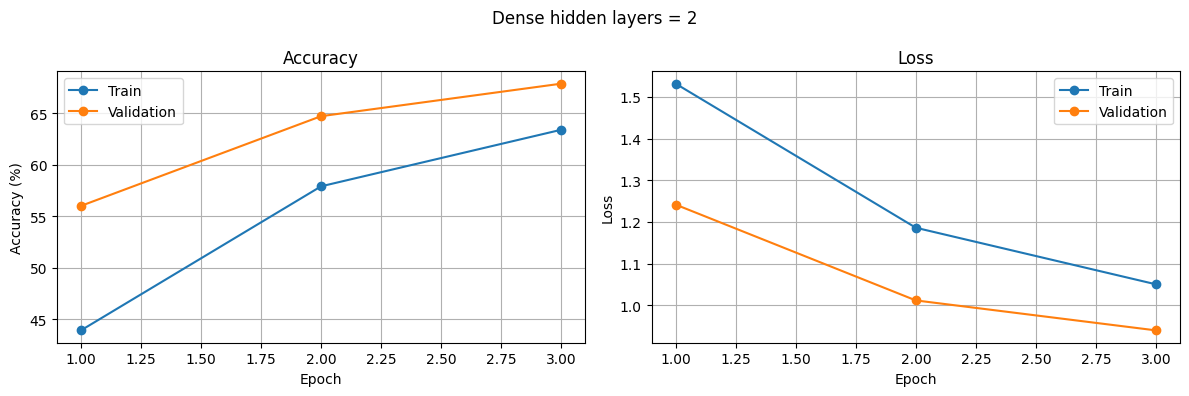


Experiment: Dense hidden layers = 3
Architecture: {'conv_channels': (32, 64), 'dense_neurons': 128, 'dense_layers': 3, 'activation': 'relu', 'padding': 'same', 'pooling': 'max', 'dropout': 0.3}
Training settings: {'batch_size': 128, 'optimizer_name': 'adam', 'lr': 0.001, 'weight_decay': 0.0}
Epoch 01/3 | Train loss 1.5850, acc 41.08% | Val loss 1.2067, acc 56.74%
Epoch 02/3 | Train loss 1.2422, acc 55.81% | Val loss 1.0676, acc 63.48%
Epoch 03/3 | Train loss 1.1025, acc 61.52% | Val loss 0.9834, acc 66.38%


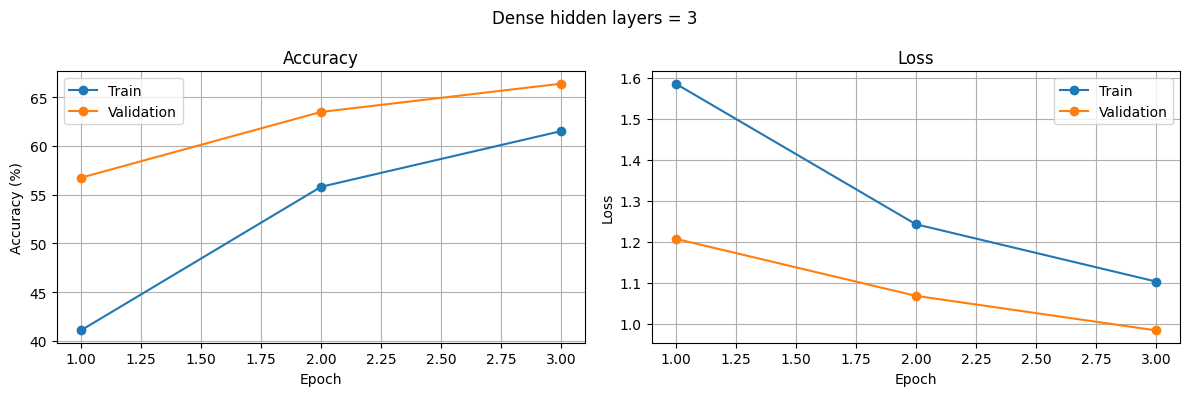

,Experiment,Conv layers,Filters,Dense layers,Dense neurons/layer,Activation,Padding,Pooling,Dropout,Optimizer,Learning rate,Batch size,Weight decay,Train accuracy (%),Validation accuracy (%),Train loss,Validation loss,Time (sec)
0,Dense hidden layers = 2,2,"(32, 64)",2,128,relu,same,max,0.3,adam,0.001,128,0.0,63.400000,67.88,1.050583,0.940203,281.713231
1,Dense neurons = 64,2,"(32, 64)",1,64,relu,same,max,0.3,adam,0.001,128,0.0,60.637778,67.18,1.096969,0.950818,282.689281
2,Dense neurons = 256,2,"(32, 64)",1,256,relu,same,max,0.3,adam,0.001,128,0.0,65.782222,66.94,0.969018,0.933620,298.363139
3,Baseline,2,"(32, 64)",1,128,relu,same,max,0.3,adam,0.001,128,0.0,65.240000,66.38,0.980732,0.945421,295.609945
4,Dense hidden layers = 3,2,"(32, 64)",3,128,relu,same,max,0.3,adam,0.001,128,0.0,61.517778,66.38,1.102491,0.983358,285.022602


,Experiment,Conv layers,Filters,Dense layers,Dense neurons/layer,Activation,Padding,Pooling,Dropout,Optimizer,Learning rate,Batch size,Weight decay,Train accuracy (%),Validation accuracy (%),Train loss,Validation loss,Time (sec)
0,Baseline,2,"(32, 64)",1,128,relu,same,max,0.3,adam,0.001,128,0.0,65.240000,66.38,0.980732,0.945421,295.609945
1,Dense neurons = 64,2,"(32, 64)",1,64,relu,same,max,0.3,adam,0.001,128,0.0,60.637778,67.18,1.096969,0.950818,282.689281
2,Dense neurons = 256,2,"(32, 64)",1,256,relu,same,max,0.3,adam,0.001,128,0.0,65.782222,66.94,0.969018,0.933620,298.363139
3,Dense hidden layers = 2,2,"(32, 64)",2,128,relu,same,max,0.3,adam,0.001,128,0.0,63.400000,67.88,1.050583,0.940203,281.713231
4,Dense hidden layers = 3,2,"(32, 64)",3,128,relu,same,max,0.3,adam,0.001,128,0.0,61.517778,66.38,1.102491,0.983358,285.022602


In [ ]:
# 8B. Fine-tune number of fully connected hidden layers
# Baseline has one hidden dense layer. Try 2 and 3.
for layers in [2, 3]:
    run_experiment(
        name=f"Dense hidden layers = {layers}",
        config_updates={"dense_layers": layers}
    )

show_results()



Experiment: Conv blocks = 1
Architecture: {'conv_channels': (32,), 'dense_neurons': 128, 'dense_layers': 1, 'activation': 'relu', 'padding': 'same', 'pooling': 'max', 'dropout': 0.3}
Training settings: {'batch_size': 128, 'optimizer_name': 'adam', 'lr': 0.001, 'weight_decay': 0.0}
Epoch 01/3 | Train loss 1.7465, acc 36.25% | Val loss 1.4217, acc 49.92%
Epoch 02/3 | Train loss 1.4719, acc 46.02% | Val loss 1.2794, acc 55.28%
Epoch 03/3 | Train loss 1.3659, acc 50.01% | Val loss 1.1992, acc 57.98%


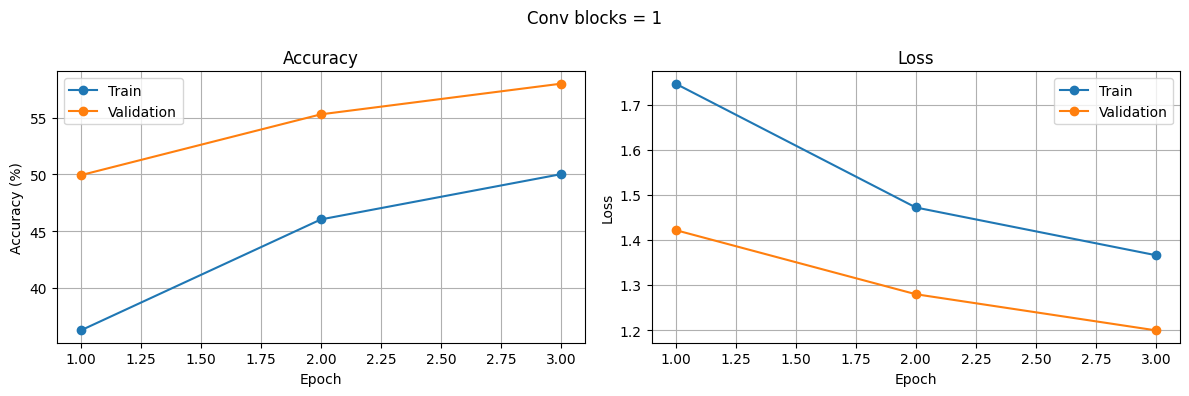


Experiment: Conv blocks = 3
Architecture: {'conv_channels': (32, 64, 128), 'dense_neurons': 128, 'dense_layers': 1, 'activation': 'relu', 'padding': 'same', 'pooling': 'max', 'dropout': 0.3}
Training settings: {'batch_size': 128, 'optimizer_name': 'adam', 'lr': 0.001, 'weight_decay': 0.0}
Epoch 01/3 | Train loss 1.3740, acc 50.38% | Val loss 1.0303, acc 63.54%
Epoch 02/3 | Train loss 1.0022, acc 64.41% | Val loss 0.9340, acc 66.08%
Epoch 03/3 | Train loss 0.8665, acc 69.50% | Val loss 0.8426, acc 70.52%


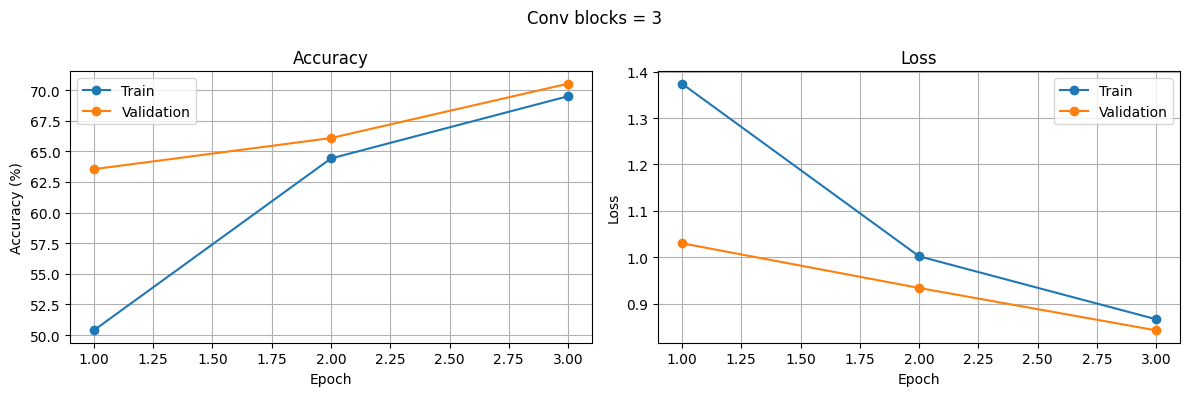

,Experiment,Conv layers,Filters,Dense layers,Dense neurons/layer,Activation,Padding,Pooling,Dropout,Optimizer,Learning rate,Batch size,Weight decay,Train accuracy (%),Validation accuracy (%),Train loss,Validation loss,Time (sec)
0,Conv blocks = 3,3,"(32, 64, 128)",1,128,relu,same,max,0.3,adam,0.001,128,0.0,69.495556,70.52,0.866474,0.842608,387.142138
1,Dense hidden layers = 2,2,"(32, 64)",2,128,relu,same,max,0.3,adam,0.001,128,0.0,63.400000,67.88,1.050583,0.940203,281.713231
2,Dense neurons = 64,2,"(32, 64)",1,64,relu,same,max,0.3,adam,0.001,128,0.0,60.637778,67.18,1.096969,0.950818,282.689281
3,Dense neurons = 256,2,"(32, 64)",1,256,relu,same,max,0.3,adam,0.001,128,0.0,65.782222,66.94,0.969018,0.933620,298.363139
4,Baseline,2,"(32, 64)",1,128,relu,same,max,0.3,adam,0.001,128,0.0,65.240000,66.38,0.980732,0.945421,295.609945
5,Dense hidden layers = 3,2,"(32, 64)",3,128,relu,same,max,0.3,adam,0.001,128,0.0,61.517778,66.38,1.102491,0.983358,285.022602
6,Conv blocks = 1,1,"(32,)",1,128,relu,same,max,0.3,adam,0.001,128,0.0,50.011111,57.98,1.365927,1.199198,184.622115


,Experiment,Conv layers,Filters,Dense layers,Dense neurons/layer,Activation,Padding,Pooling,Dropout,Optimizer,Learning rate,Batch size,Weight decay,Train accuracy (%),Validation accuracy (%),Train loss,Validation loss,Time (sec)
0,Baseline,2,"(32, 64)",1,128,relu,same,max,0.3,adam,0.001,128,0.0,65.240000,66.38,0.980732,0.945421,295.609945
1,Dense neurons = 64,2,"(32, 64)",1,64,relu,same,max,0.3,adam,0.001,128,0.0,60.637778,67.18,1.096969,0.950818,282.689281
2,Dense neurons = 256,2,"(32, 64)",1,256,relu,same,max,0.3,adam,0.001,128,0.0,65.782222,66.94,0.969018,0.933620,298.363139
3,Dense hidden layers = 2,2,"(32, 64)",2,128,relu,same,max,0.3,adam,0.001,128,0.0,63.400000,67.88,1.050583,0.940203,281.713231
4,Dense hidden layers = 3,2,"(32, 64)",3,128,relu,same,max,0.3,adam,0.001,128,0.0,61.517778,66.38,1.102491,0.983358,285.022602
5,Conv blocks = 1,1,"(32,)",1,128,relu,same,max,0.3,adam,0.001,128,0.0,50.011111,57.98,1.365927,1.199198,184.622115
6,Conv blocks = 3,3,"(32, 64, 128)",1,128,relu,same,max,0.3,adam,0.001,128,0.0,69.495556,70.52,0.866474,0.842608,387.142138


In [ ]:
# 8C. Fine-tune number of convolutional layers
# Compare 1 and 3 conv blocks against baseline (2 blocks).
for channels in [(32,), (32, 64, 128)]:
    run_experiment(
        name=f"Conv blocks = {len(channels)}",
        config_updates={"conv_channels": channels}
    )

show_results()



Experiment: Filters = (16, 32)
Architecture: {'conv_channels': (16, 32), 'dense_neurons': 128, 'dense_layers': 1, 'activation': 'relu', 'padding': 'same', 'pooling': 'max', 'dropout': 0.3}
Training settings: {'batch_size': 128, 'optimizer_name': 'adam', 'lr': 0.001, 'weight_decay': 0.0}
Epoch 01/3 | Train loss 1.4997, acc 45.61% | Val loss 1.1978, acc 58.50%
Epoch 02/3 | Train loss 1.1817, acc 57.96% | Val loss 1.1618, acc 59.18%
Epoch 03/3 | Train loss 1.0659, acc 62.26% | Val loss 0.9718, acc 66.16%


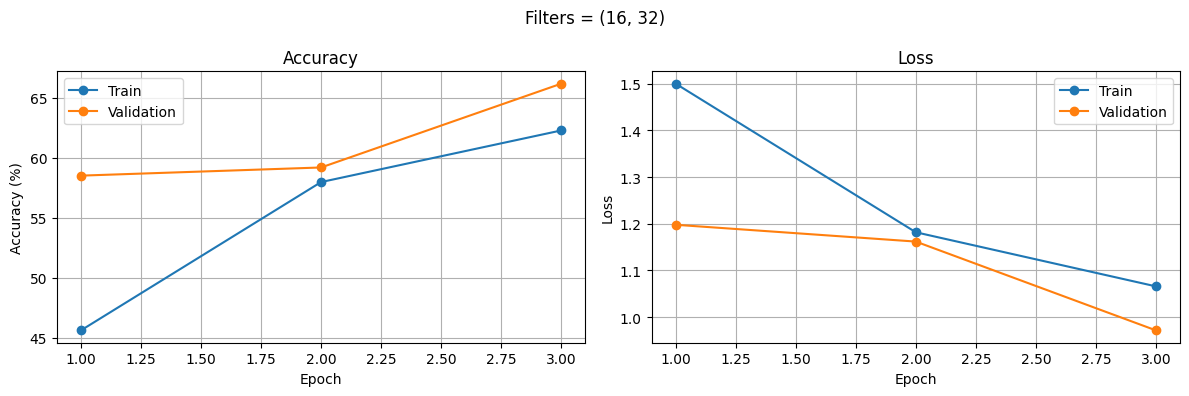


Experiment: Filters = (64, 128)
Architecture: {'conv_channels': (64, 128), 'dense_neurons': 128, 'dense_layers': 1, 'activation': 'relu', 'padding': 'same', 'pooling': 'max', 'dropout': 0.3}
Training settings: {'batch_size': 128, 'optimizer_name': 'adam', 'lr': 0.001, 'weight_decay': 0.0}
Epoch 01/3 | Train loss 1.6493, acc 39.46% | Val loss 1.2521, acc 54.90%
Epoch 02/3 | Train loss 1.2784, acc 52.93% | Val loss 1.0882, acc 61.46%
Epoch 03/3 | Train loss 1.1585, acc 57.79% | Val loss 0.9786, acc 65.76%


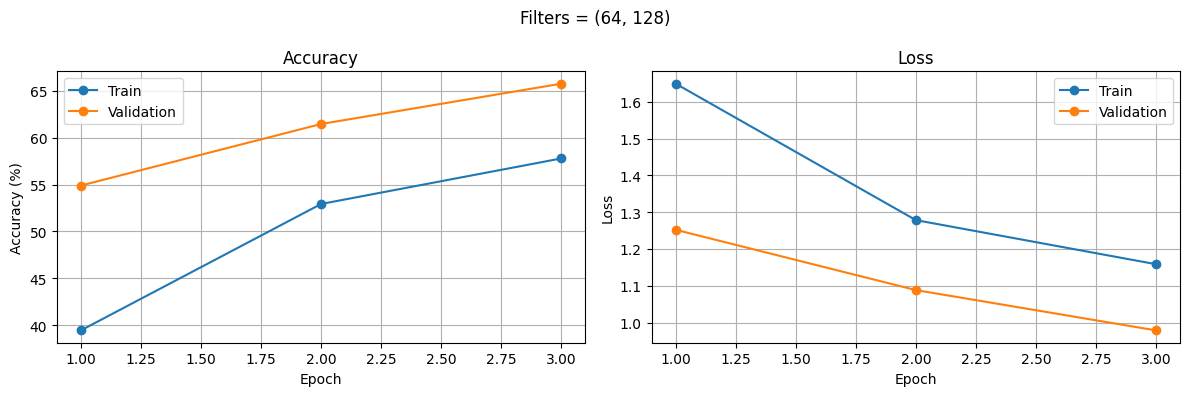

,Experiment,Conv layers,Filters,Dense layers,Dense neurons/layer,Activation,Padding,Pooling,Dropout,Optimizer,Learning rate,Batch size,Weight decay,Train accuracy (%),Validation accuracy (%),Train loss,Validation loss,Time (sec)
0,Conv blocks = 3,3,"(32, 64, 128)",1,128,relu,same,max,0.3,adam,0.001,128,0.0,69.495556,70.52,0.866474,0.842608,387.142138
1,Dense hidden layers = 2,2,"(32, 64)",2,128,relu,same,max,0.3,adam,0.001,128,0.0,63.400000,67.88,1.050583,0.940203,281.713231
2,Dense neurons = 64,2,"(32, 64)",1,64,relu,same,max,0.3,adam,0.001,128,0.0,60.637778,67.18,1.096969,0.950818,282.689281
3,Dense neurons = 256,2,"(32, 64)",1,256,relu,same,max,0.3,adam,0.001,128,0.0,65.782222,66.94,0.969018,0.933620,298.363139
4,Baseline,2,"(32, 64)",1,128,relu,same,max,0.3,adam,0.001,128,0.0,65.240000,66.38,0.980732,0.945421,295.609945
5,Dense hidden layers = 3,2,"(32, 64)",3,128,relu,same,max,0.3,adam,0.001,128,0.0,61.517778,66.38,1.102491,0.983358,285.022602
6,"Filters = (16, 32)",2,"(16, 32)",1,128,relu,same,max,0.3,adam,0.001,128,0.0,62.264444,66.16,1.065928,0.971765,143.042640
7,"Filters = (64, 128)",2,"(64, 128)",1,128,relu,same,max,0.3,adam,0.001,128,0.0,57.788889,65.76,1.158522,0.978587,871.973327
8,Conv blocks = 1,1,"(32,)",1,128,relu,same,max,0.3,adam,0.001,128,0.0,50.011111,57.98,1.365927,1.199198,184.622115


,Experiment,Conv layers,Filters,Dense layers,Dense neurons/layer,Activation,Padding,Pooling,Dropout,Optimizer,Learning rate,Batch size,Weight decay,Train accuracy (%),Validation accuracy (%),Train loss,Validation loss,Time (sec)
0,Baseline,2,"(32, 64)",1,128,relu,same,max,0.3,adam,0.001,128,0.0,65.240000,66.38,0.980732,0.945421,295.609945
1,Dense neurons = 64,2,"(32, 64)",1,64,relu,same,max,0.3,adam,0.001,128,0.0,60.637778,67.18,1.096969,0.950818,282.689281
2,Dense neurons = 256,2,"(32, 64)",1,256,relu,same,max,0.3,adam,0.001,128,0.0,65.782222,66.94,0.969018,0.933620,298.363139
3,Dense hidden layers = 2,2,"(32, 64)",2,128,relu,same,max,0.3,adam,0.001,128,0.0,63.400000,67.88,1.050583,0.940203,281.713231
4,Dense hidden layers = 3,2,"(32, 64)",3,128,relu,same,max,0.3,adam,0.001,128,0.0,61.517778,66.38,1.102491,0.983358,285.022602
5,Conv blocks = 1,1,"(32,)",1,128,relu,same,max,0.3,adam,0.001,128,0.0,50.011111,57.98,1.365927,1.199198,184.622115
6,Conv blocks = 3,3,"(32, 64, 128)",1,128,relu,same,max,0.3,adam,0.001,128,0.0,69.495556,70.52,0.866474,0.842608,387.142138
7,"Filters = (16, 32)",2,"(16, 32)",1,128,relu,same,max,0.3,adam,0.001,128,0.0,62.264444,66.16,1.065928,0.971765,143.042640
8,"Filters = (64, 128)",2,"(64, 128)",1,128,relu,same,max,0.3,adam,0.001,128,0.0,57.788889,65.76,1.158522,0.978587,871.973327


In [ ]:
# 8D. Fine-tune filter counts
# Compare fewer filters and more filters. Number of conv layers stays at 2.
for channels in [(16, 32), (64, 128)]:
    run_experiment(
        name=f"Filters = {channels}",
        config_updates={"conv_channels": channels}
    )

show_results()



Experiment: Activation = leaky_relu
Architecture: {'conv_channels': (32, 64), 'dense_neurons': 128, 'dense_layers': 1, 'activation': 'leaky_relu', 'padding': 'same', 'pooling': 'max', 'dropout': 0.3}
Training settings: {'batch_size': 128, 'optimizer_name': 'adam', 'lr': 0.001, 'weight_decay': 0.0}
Epoch 01/3 | Train loss 1.4268, acc 48.49% | Val loss 1.1223, acc 60.06%
Epoch 02/3 | Train loss 1.1130, acc 60.27% | Val loss 1.0242, acc 63.20%
Epoch 03/3 | Train loss 0.9896, acc 64.89% | Val loss 0.9392, acc 67.02%


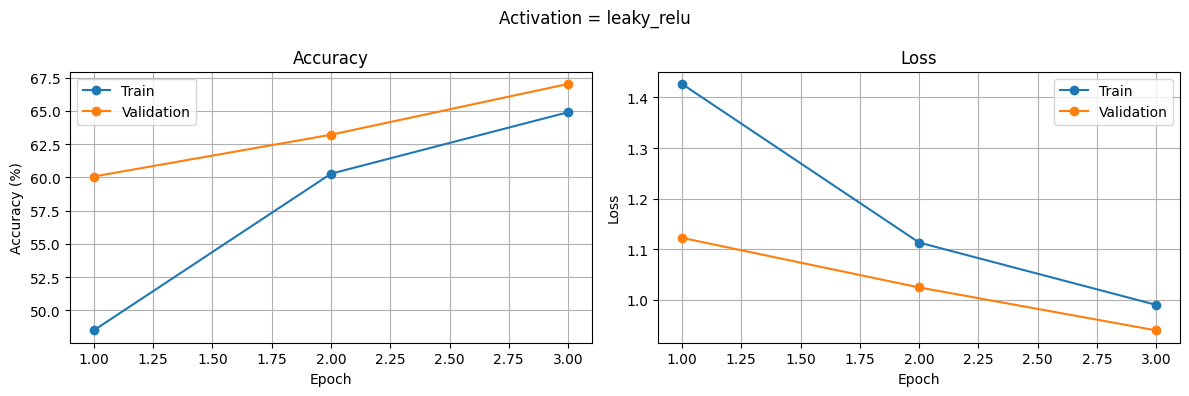


Experiment: Activation = tanh
Architecture: {'conv_channels': (32, 64), 'dense_neurons': 128, 'dense_layers': 1, 'activation': 'tanh', 'padding': 'same', 'pooling': 'max', 'dropout': 0.3}
Training settings: {'batch_size': 128, 'optimizer_name': 'adam', 'lr': 0.001, 'weight_decay': 0.0}
Epoch 01/3 | Train loss 1.4729, acc 47.31% | Val loss 1.2214, acc 56.70%
Epoch 02/3 | Train loss 1.1769, acc 58.27% | Val loss 1.1248, acc 59.68%
Epoch 03/3 | Train loss 1.0740, acc 62.11% | Val loss 1.0073, acc 64.84%


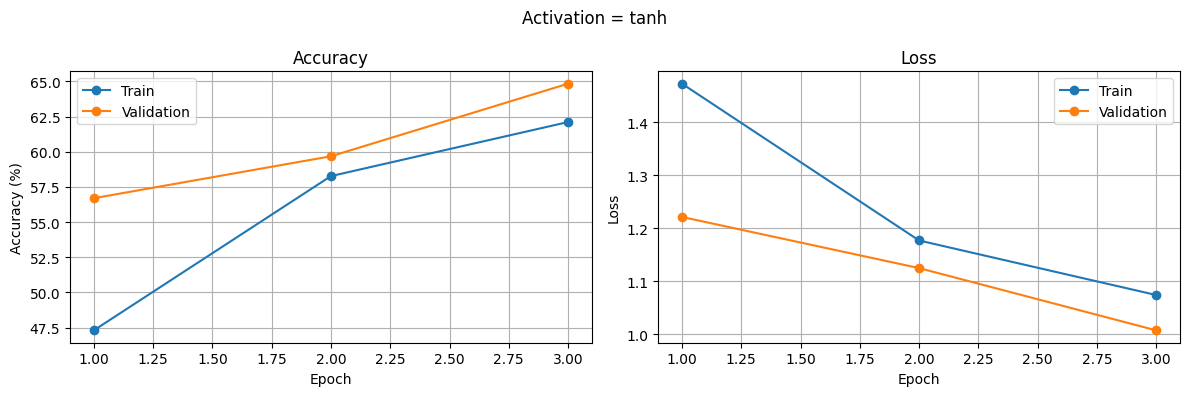

,Experiment,Conv layers,Filters,Dense layers,Dense neurons/layer,Activation,Padding,Pooling,Dropout,Optimizer,Learning rate,Batch size,Weight decay,Train accuracy (%),Validation accuracy (%),Train loss,Validation loss,Time (sec)
0,Conv blocks = 3,3,"(32, 64, 128)",1,128,relu,same,max,0.3,adam,0.001,128,0.0,69.495556,70.52,0.866474,0.842608,387.142138
1,Dense hidden layers = 2,2,"(32, 64)",2,128,relu,same,max,0.3,adam,0.001,128,0.0,63.400000,67.88,1.050583,0.940203,281.713231
2,Dense neurons = 64,2,"(32, 64)",1,64,relu,same,max,0.3,adam,0.001,128,0.0,60.637778,67.18,1.096969,0.950818,282.689281
3,Activation = leaky_relu,2,"(32, 64)",1,128,leaky_relu,same,max,0.3,adam,0.001,128,0.0,64.893333,67.02,0.989582,0.939170,309.461701
4,Dense neurons = 256,2,"(32, 64)",1,256,relu,same,max,0.3,adam,0.001,128,0.0,65.782222,66.94,0.969018,0.933620,298.363139
5,Baseline,2,"(32, 64)",1,128,relu,same,max,0.3,adam,0.001,128,0.0,65.240000,66.38,0.980732,0.945421,295.609945
6,Dense hidden layers = 3,2,"(32, 64)",3,128,relu,same,max,0.3,adam,0.001,128,0.0,61.517778,66.38,1.102491,0.983358,285.022602
7,"Filters = (16, 32)",2,"(16, 32)",1,128,relu,same,max,0.3,adam,0.001,128,0.0,62.264444,66.16,1.065928,0.971765,143.042640
8,"Filters = (64, 128)",2,"(64, 128)",1,128,relu,same,max,0.3,adam,0.001,128,0.0,57.788889,65.76,1.158522,0.978587,871.973327
9,Activation = tanh,2,"(32, 64)",1,128,tanh,same,max,0.3,adam,0.001,128,0.0,62.113333,64.84,1.073975,1.007271,301.691383


,Experiment,Conv layers,Filters,Dense layers,Dense neurons/layer,Activation,Padding,Pooling,Dropout,Optimizer,Learning rate,Batch size,Weight decay,Train accuracy (%),Validation accuracy (%),Train loss,Validation loss,Time (sec)
0,Baseline,2,"(32, 64)",1,128,relu,same,max,0.3,adam,0.001,128,0.0,65.240000,66.38,0.980732,0.945421,295.609945
1,Dense neurons = 64,2,"(32, 64)",1,64,relu,same,max,0.3,adam,0.001,128,0.0,60.637778,67.18,1.096969,0.950818,282.689281
2,Dense neurons = 256,2,"(32, 64)",1,256,relu,same,max,0.3,adam,0.001,128,0.0,65.782222,66.94,0.969018,0.933620,298.363139
3,Dense hidden layers = 2,2,"(32, 64)",2,128,relu,same,max,0.3,adam,0.001,128,0.0,63.400000,67.88,1.050583,0.940203,281.713231
4,Dense hidden layers = 3,2,"(32, 64)",3,128,relu,same,max,0.3,adam,0.001,128,0.0,61.517778,66.38,1.102491,0.983358,285.022602
5,Conv blocks = 1,1,"(32,)",1,128,relu,same,max,0.3,adam,0.001,128,0.0,50.011111,57.98,1.365927,1.199198,184.622115
6,Conv blocks = 3,3,"(32, 64, 128)",1,128,relu,same,max,0.3,adam,0.001,128,0.0,69.495556,70.52,0.866474,0.842608,387.142138
7,"Filters = (16, 32)",2,"(16, 32)",1,128,relu,same,max,0.3,adam,0.001,128,0.0,62.264444,66.16,1.065928,0.971765,143.042640
8,"Filters = (64, 128)",2,"(64, 128)",1,128,relu,same,max,0.3,adam,0.001,128,0.0,57.788889,65.76,1.158522,0.978587,871.973327
9,Activation = leaky_relu,2,"(32, 64)",1,128,leaky_relu,same,max,0.3,adam,0.001,128,0.0,64.893333,67.02,0.989582,0.939170,309.461701


In [ ]:
# 8E. Fine-tune activation functions
for activation in ["leaky_relu", "tanh"]:
    run_experiment(
        name=f"Activation = {activation}",
        config_updates={"activation": activation}
    )

show_results()



Experiment: Padding = valid
Architecture: {'conv_channels': (32, 64), 'dense_neurons': 128, 'dense_layers': 1, 'activation': 'relu', 'padding': 'valid', 'pooling': 'max', 'dropout': 0.3}
Training settings: {'batch_size': 128, 'optimizer_name': 'adam', 'lr': 0.001, 'weight_decay': 0.0}
Epoch 01/3 | Train loss 1.4127, acc 48.91% | Val loss 1.1213, acc 61.12%
Epoch 02/3 | Train loss 1.1086, acc 60.88% | Val loss 0.9855, acc 65.34%
Epoch 03/3 | Train loss 0.9918, acc 65.08% | Val loss 0.9406, acc 66.52%


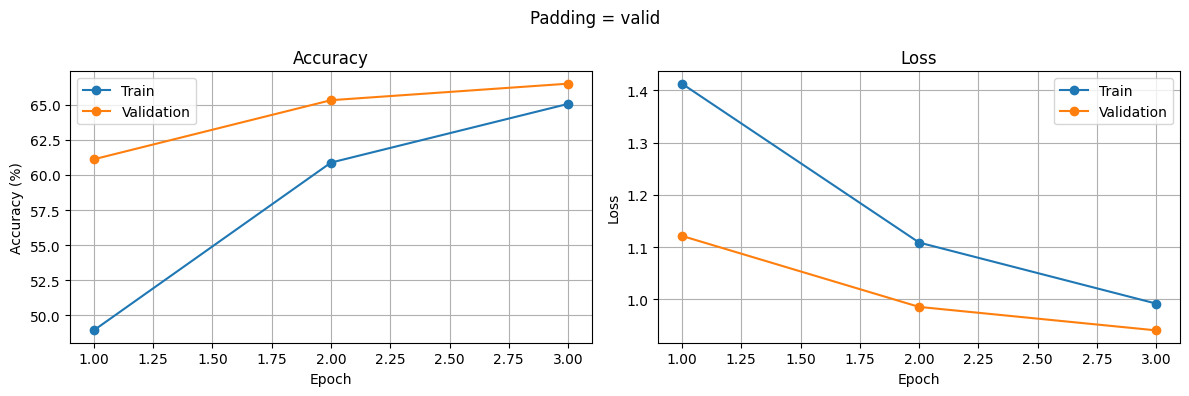

,Experiment,Conv layers,Filters,Dense layers,Dense neurons/layer,Activation,Padding,Pooling,Dropout,Optimizer,Learning rate,Batch size,Weight decay,Train accuracy (%),Validation accuracy (%),Train loss,Validation loss,Time (sec)
0,Conv blocks = 3,3,"(32, 64, 128)",1,128,relu,same,max,0.3,adam,0.001,128,0.0,69.495556,70.52,0.866474,0.842608,387.142138
1,Dense hidden layers = 2,2,"(32, 64)",2,128,relu,same,max,0.3,adam,0.001,128,0.0,63.400000,67.88,1.050583,0.940203,281.713231
2,Dense neurons = 64,2,"(32, 64)",1,64,relu,same,max,0.3,adam,0.001,128,0.0,60.637778,67.18,1.096969,0.950818,282.689281
3,Activation = leaky_relu,2,"(32, 64)",1,128,leaky_relu,same,max,0.3,adam,0.001,128,0.0,64.893333,67.02,0.989582,0.939170,309.461701
4,Dense neurons = 256,2,"(32, 64)",1,256,relu,same,max,0.3,adam,0.001,128,0.0,65.782222,66.94,0.969018,0.933620,298.363139
5,Padding = valid,2,"(32, 64)",1,128,relu,valid,max,0.3,adam,0.001,128,0.0,65.077778,66.52,0.991776,0.940562,226.674819
6,Baseline,2,"(32, 64)",1,128,relu,same,max,0.3,adam,0.001,128,0.0,65.240000,66.38,0.980732,0.945421,295.609945
7,Dense hidden layers = 3,2,"(32, 64)",3,128,relu,same,max,0.3,adam,0.001,128,0.0,61.517778,66.38,1.102491,0.983358,285.022602
8,"Filters = (16, 32)",2,"(16, 32)",1,128,relu,same,max,0.3,adam,0.001,128,0.0,62.264444,66.16,1.065928,0.971765,143.042640
9,"Filters = (64, 128)",2,"(64, 128)",1,128,relu,same,max,0.3,adam,0.001,128,0.0,57.788889,65.76,1.158522,0.978587,871.973327


,Experiment,Conv layers,Filters,Dense layers,Dense neurons/layer,Activation,Padding,Pooling,Dropout,Optimizer,Learning rate,Batch size,Weight decay,Train accuracy (%),Validation accuracy (%),Train loss,Validation loss,Time (sec)
0,Baseline,2,"(32, 64)",1,128,relu,same,max,0.3,adam,0.001,128,0.0,65.240000,66.38,0.980732,0.945421,295.609945
1,Dense neurons = 64,2,"(32, 64)",1,64,relu,same,max,0.3,adam,0.001,128,0.0,60.637778,67.18,1.096969,0.950818,282.689281
2,Dense neurons = 256,2,"(32, 64)",1,256,relu,same,max,0.3,adam,0.001,128,0.0,65.782222,66.94,0.969018,0.933620,298.363139
3,Dense hidden layers = 2,2,"(32, 64)",2,128,relu,same,max,0.3,adam,0.001,128,0.0,63.400000,67.88,1.050583,0.940203,281.713231
4,Dense hidden layers = 3,2,"(32, 64)",3,128,relu,same,max,0.3,adam,0.001,128,0.0,61.517778,66.38,1.102491,0.983358,285.022602
5,Conv blocks = 1,1,"(32,)",1,128,relu,same,max,0.3,adam,0.001,128,0.0,50.011111,57.98,1.365927,1.199198,184.622115
6,Conv blocks = 3,3,"(32, 64, 128)",1,128,relu,same,max,0.3,adam,0.001,128,0.0,69.495556,70.52,0.866474,0.842608,387.142138
7,"Filters = (16, 32)",2,"(16, 32)",1,128,relu,same,max,0.3,adam,0.001,128,0.0,62.264444,66.16,1.065928,0.971765,143.042640
8,"Filters = (64, 128)",2,"(64, 128)",1,128,relu,same,max,0.3,adam,0.001,128,0.0,57.788889,65.76,1.158522,0.978587,871.973327
9,Activation = leaky_relu,2,"(32, 64)",1,128,leaky_relu,same,max,0.3,adam,0.001,128,0.0,64.893333,67.02,0.989582,0.939170,309.461701


In [ ]:
# 8F. Fine-tune padding
# Valid padding reduces spatial dimensions; ensure image dimensions remain large enough.
run_experiment(
    name="Padding = valid",
    config_updates={"padding": "valid"}
)
show_results()



Experiment: Pooling = average
Architecture: {'conv_channels': (32, 64), 'dense_neurons': 128, 'dense_layers': 1, 'activation': 'relu', 'padding': 'same', 'pooling': 'avg', 'dropout': 0.3}
Training settings: {'batch_size': 128, 'optimizer_name': 'adam', 'lr': 0.001, 'weight_decay': 0.0}
Epoch 01/3 | Train loss 1.4162, acc 48.93% | Val loss 1.1690, acc 58.30%
Epoch 02/3 | Train loss 1.1053, acc 60.60% | Val loss 1.0141, acc 64.56%
Epoch 03/3 | Train loss 0.9836, acc 65.07% | Val loss 0.9217, acc 67.68%


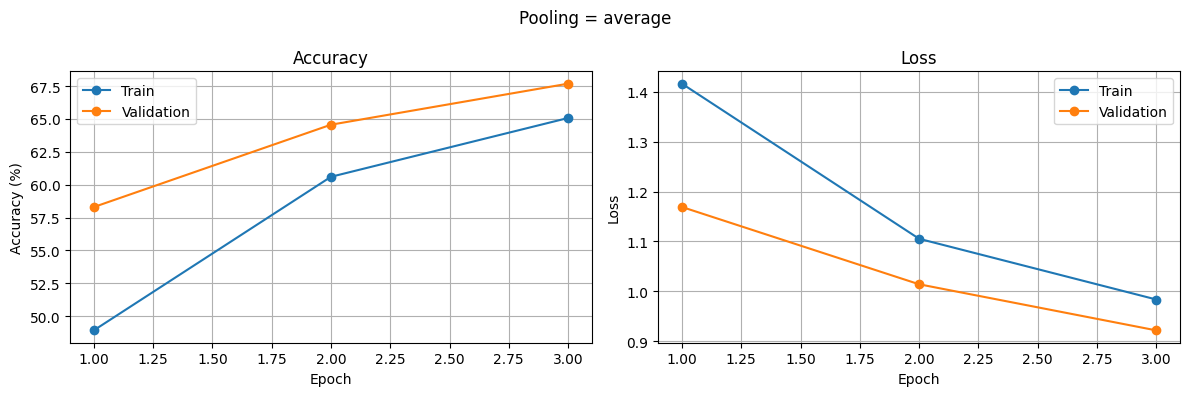

,Experiment,Conv layers,Filters,Dense layers,Dense neurons/layer,Activation,Padding,Pooling,Dropout,Optimizer,Learning rate,Batch size,Weight decay,Train accuracy (%),Validation accuracy (%),Train loss,Validation loss,Time (sec)
0,Conv blocks = 3,3,"(32, 64, 128)",1,128,relu,same,max,0.3,adam,0.001,128,0.0,69.495556,70.52,0.866474,0.842608,387.142138
1,Dense hidden layers = 2,2,"(32, 64)",2,128,relu,same,max,0.3,adam,0.001,128,0.0,63.400000,67.88,1.050583,0.940203,281.713231
2,Pooling = average,2,"(32, 64)",1,128,relu,same,avg,0.3,adam,0.001,128,0.0,65.071111,67.68,0.983616,0.921720,320.513752
3,Dense neurons = 64,2,"(32, 64)",1,64,relu,same,max,0.3,adam,0.001,128,0.0,60.637778,67.18,1.096969,0.950818,282.689281
4,Activation = leaky_relu,2,"(32, 64)",1,128,leaky_relu,same,max,0.3,adam,0.001,128,0.0,64.893333,67.02,0.989582,0.939170,309.461701
5,Dense neurons = 256,2,"(32, 64)",1,256,relu,same,max,0.3,adam,0.001,128,0.0,65.782222,66.94,0.969018,0.933620,298.363139
6,Padding = valid,2,"(32, 64)",1,128,relu,valid,max,0.3,adam,0.001,128,0.0,65.077778,66.52,0.991776,0.940562,226.674819
7,Dense hidden layers = 3,2,"(32, 64)",3,128,relu,same,max,0.3,adam,0.001,128,0.0,61.517778,66.38,1.102491,0.983358,285.022602
8,Baseline,2,"(32, 64)",1,128,relu,same,max,0.3,adam,0.001,128,0.0,65.240000,66.38,0.980732,0.945421,295.609945
9,"Filters = (16, 32)",2,"(16, 32)",1,128,relu,same,max,0.3,adam,0.001,128,0.0,62.264444,66.16,1.065928,0.971765,143.042640


,Experiment,Conv layers,Filters,Dense layers,Dense neurons/layer,Activation,Padding,Pooling,Dropout,Optimizer,Learning rate,Batch size,Weight decay,Train accuracy (%),Validation accuracy (%),Train loss,Validation loss,Time (sec)
0,Baseline,2,"(32, 64)",1,128,relu,same,max,0.3,adam,0.001,128,0.0,65.240000,66.38,0.980732,0.945421,295.609945
1,Dense neurons = 64,2,"(32, 64)",1,64,relu,same,max,0.3,adam,0.001,128,0.0,60.637778,67.18,1.096969,0.950818,282.689281
2,Dense neurons = 256,2,"(32, 64)",1,256,relu,same,max,0.3,adam,0.001,128,0.0,65.782222,66.94,0.969018,0.933620,298.363139
3,Dense hidden layers = 2,2,"(32, 64)",2,128,relu,same,max,0.3,adam,0.001,128,0.0,63.400000,67.88,1.050583,0.940203,281.713231
4,Dense hidden layers = 3,2,"(32, 64)",3,128,relu,same,max,0.3,adam,0.001,128,0.0,61.517778,66.38,1.102491,0.983358,285.022602
5,Conv blocks = 1,1,"(32,)",1,128,relu,same,max,0.3,adam,0.001,128,0.0,50.011111,57.98,1.365927,1.199198,184.622115
6,Conv blocks = 3,3,"(32, 64, 128)",1,128,relu,same,max,0.3,adam,0.001,128,0.0,69.495556,70.52,0.866474,0.842608,387.142138
7,"Filters = (16, 32)",2,"(16, 32)",1,128,relu,same,max,0.3,adam,0.001,128,0.0,62.264444,66.16,1.065928,0.971765,143.042640
8,"Filters = (64, 128)",2,"(64, 128)",1,128,relu,same,max,0.3,adam,0.001,128,0.0,57.788889,65.76,1.158522,0.978587,871.973327
9,Activation = leaky_relu,2,"(32, 64)",1,128,leaky_relu,same,max,0.3,adam,0.001,128,0.0,64.893333,67.02,0.989582,0.939170,309.461701


In [ ]:
# 8G. Fine-tune pooling method
run_experiment(
    name="Pooling = average",
    config_updates={"pooling": "avg"}
)
show_results()


## 9. Training hyperparameter experiments

Again, change one training parameter at a time. The following cells compare optimizers, learning rates, dropout, batch size, and weight decay.


In [ ]:
# 9A. Compare optimizers: Adam, SGD, RMSprop
for opt_name in ["sgd", "rmsprop"]:
    run_experiment(
        name=f"Optimizer = {opt_name}",
        training_updates={"optimizer_name": opt_name}
    )

show_results()


In [ ]:
# 9B. Compare learning rates
for lr_value in [0.01, 0.0001]:
    run_experiment(
        name=f"Learning rate = {lr_value}",
        training_updates={"lr": lr_value}
    )

show_results()


In [ ]:
# 9C. Compare dropout values
for drop_value in [0.1, 0.5]:
    run_experiment(
        name=f"Dropout = {drop_value}",
        config_updates={"dropout": drop_value}
    )

show_results()


In [ ]:
# 9D. Compare batch sizes
for batch_value in [64, 256]:
    run_experiment(
        name=f"Batch size = {batch_value}",
        training_updates={"batch_size": batch_value}
    )

show_results()


In [ ]:
# 9E. Compare weight decay (L2 regularization)
for wd_value in [0.0001, 0.001]:
    run_experiment(
        name=f"Weight decay = {wd_value}",
        training_updates={"weight_decay": wd_value}
    )

show_results()


In [ ]:
# 10. Final comparison: sort by validation accuracy
results_df = show_results()

# Optional: export results to CSV for your lab report
if results_df is not None:
    results_df.to_csv("cnn_hyperparameter_results.csv", index=False)
    print("Saved: cnn_hyperparameter_results.csv")


In [ ]:
# 11. Evaluate the baseline model on the held-out test dataset
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False,
                         num_workers=2, pin_memory=(device.type=="cuda"))
criterion = nn.CrossEntropyLoss()
test_loss, test_acc = run_epoch(
    baseline_result["model"], test_loader, criterion, optimizer=None
)
print(f"Baseline test loss: {test_loss:.4f}")
print(f"Baseline test accuracy: {test_acc:.2f}%")


In [ ]:
# 12. Visualize filters learned by the first convolutional layer
# The first layer has 3 input channels (RGB) and 32 output filters.
model_to_visualize = baseline_result["model"]
first_conv = next(layer for layer in model_to_visualize.modules()
                  if isinstance(layer, nn.Conv2d))
filters = first_conv.weight.detach().cpu()

fig, axes = plt.subplots(4, 8, figsize=(12, 6))
for i, ax in enumerate(axes.flat):
    filt = filters[i]
    # Normalize each filter separately for visualization.
    filt = (filt - filt.min()) / (filt.max() - filt.min() + 1e-8)
    ax.imshow(filt.permute(1, 2, 0))
    ax.set_title(f"Filter {i+1}")
    ax.axis("off")
plt.suptitle("First Convolutional Layer Filters")
plt.tight_layout()
plt.show()


In [ ]:
# 13. Visualize feature maps after the first convolution
model_to_visualize.eval()
images, labels = next(iter(DataLoader(test_dataset, batch_size=1, shuffle=True)))
image = images.to(device)

conv1 = next(layer for layer in model_to_visualize.features
              if isinstance(layer, nn.Conv2d))

with torch.no_grad():
    feature_maps = conv1(image).cpu()[0]  # shape: (number of filters, H, W)

num_maps = min(16, feature_maps.shape[0])
fig, axes = plt.subplots(4, 4, figsize=(10, 8))
for i, ax in enumerate(axes.flat):
    if i < num_maps:
        ax.imshow(feature_maps[i], cmap="viridis")
        ax.set_title(f"Feature map {i+1}")
    ax.axis("off")
plt.suptitle(f"First Conv Feature Maps | True label: {class_names[labels[0]]}")
plt.tight_layout()
plt.show()


# 14. Student analysis (complete in your report)

Answer based on your **observed results**:

1. Which configuration achieved the highest validation accuracy?
2. Did a deeper CNN always perform better? Explain with evidence.
3. How did increasing filters affect training time and accuracy?
4. Compare ReLU, Leaky ReLU, and Tanh in your experiments.
5. Explain the observed difference between `same` and `valid` padding.
6. Compare max pooling and average pooling.
7. Which optimizer and learning rate converged most effectively?
8. How did dropout affect the training–validation gap?
9. Did batch size change training time or validation performance?
10. Did weight decay reduce overfitting in your experiment?
11. Recommend a final configuration and justify it using validation accuracy, loss, and time.

## Important notes
- Do not select a model using test accuracy. Use validation results for model selection and evaluate the test set only for the final selected model.
- CIFAR-10 experiments can take considerable time. Use fewer epochs initially, then rerun the best configurations for more epochs.
- Small changes in results are expected because training is stochastic.
- The experiment runner trains a fresh model for each configuration.
